# Tech Challenge Fase 1: Case NPS Preditivo

**Aluna:** Viviane Neris Campos

**Pergunta do negócio:** quais fatores operacionais influenciam a satisfação (NPS) do cliente, e como agir antes da pesquisa?

Este notebook faz: (1) carga e checagem da base, (2) definição do target e do risco de leakage, (3) análise exploratória (EDA) com foco em negócio e (4) um modelo simples (opcional) para estimar o NPS antes da pesquisa.

## 1. Carga e visão geral

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

# pasta onde salvamos os gráficos
os.makedirs('../reports/figuras', exist_ok=True)   

# Caminho para encontrar o arquivo csv
df = pd.read_csv('../data/desafio_nps_fase_1.csv')

print(df.shape)                       # linhas x colunas
print('Valores ausentes:', df.isna().sum().sum())
print('customer_id único:', df['customer_id'].is_unique, '| order_id único:', df['order_id'].is_unique)
print('Linhas duplicadas:', df.duplicated().sum())
df.head()

(2500, 19)
Valores ausentes: 0
customer_id único: True | order_id único: True
Linhas duplicadas: 0


,customer_id,customer_age,customer_region,customer_tenure_months,order_id,order_value,items_quantity,discount_value,payment_installments,delivery_time_days,delivery_delay_days,freight_value,delivery_attempts,customer_service_contacts,resolution_time_days,nps_score,repeat_purchase_30d,complaints_count,csat_internal_score
0,1,63,Nordeste,14,50001,139.73,4,39.35,4,2,2,55.53,3,0,4,6.9,0,3,6.5
1,2,20,Sul,1,50002,458.95,2,9.51,10,6,4,28.23,3,0,10,2.4,0,3,0.0
2,3,46,Nordeste,111,50003,507.06,5,42.82,6,6,1,40.99,1,4,5,4.8,0,7,1.5
3,4,52,Centro-Oeste,117,50004,302.19,2,19.58,9,5,2,35.24,3,1,11,5.9,0,4,0.3
4,5,56,Norte,50,50005,253.06,1,29.37,11,13,1,39.32,1,1,0,6.1,0,3,7.9


**Conclusão:** a base tem 2.500 pedidos e 19 colunas, sem valores ausentes e sem duplicatas. Cada linha é um pedido de um cliente (unidade de análise = pedido).

## 2. Target: nps_score

O target é `nps_score` (nota de 0 a 10, coletada depois da compra).

Esta célula cria o grupo de cada cliente a partir da nota: detrator (< 7), neutro (7 até < 9) ou promotor (≥ 9). Depois conta quantos clientes há em cada grupo, calcula o NPS clássico (% promotores − % detratores) e mostra a nota média e o gráfico da distribuição das notas.

`np.where` funciona como um "se": se a condição é verdadeira, usa um valor; senão, usa outro. `value_counts()` conta quantos clientes há em cada grupo e, com `normalize=True`, mostra a proporção.


           clientes  proporção
grupo_nps                     
detrator       2109      0.844
neutro          281      0.112
promotor        110      0.044

NPS clássico: -80.0
Nota média: 4.38
Notas exatamente 0: 158 | exatamente 10: 42


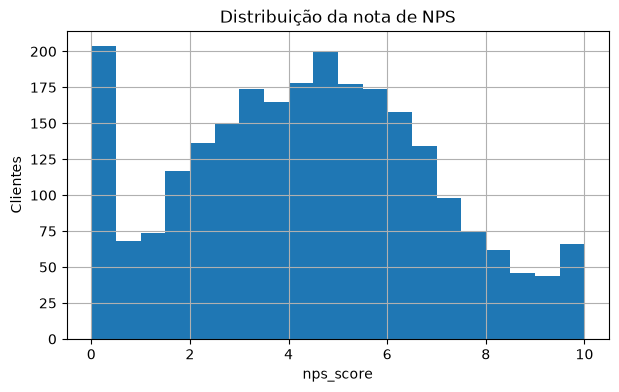

In [2]:
# Cria a coluna 'grupo_nps' com a regra do NPS, usando "se" encadeados:
#   nota < 7  -> detrator
#   nota < 9  -> neutro (7 até menos de 9)
#   senão     -> promotor (9 ou mais)
df['grupo_nps'] = np.where(df['nps_score'] < 7, 'detrator',
                   np.where(df['nps_score'] < 9, 'neutro', 'promotor'))

# Conta quantos clientes há em cada grupo
contagem = df['grupo_nps'].value_counts()

# Mesma conta, em proporção (0,844 = 84,4%); round(3) deixa 3 casas decimais
proporcao = df['grupo_nps'].value_counts(normalize=True).round(3)

# Junta as duas tabelas lado a lado: quantidade e proporção
print(pd.concat([contagem, proporcao], axis=1, keys=['clientes', 'proporção']))

# NPS clássico = % promotores - % detratores (multiplica por 100 para virar %)
nps_classico = (proporcao['promotor'] - proporcao['detrator']) * 100
print('\nNPS clássico:', round(nps_classico, 1))

# Nota média de todos os clientes
print('Nota média:', round(df['nps_score'].mean(), 2))

# Quantos clientes deram exatamente 0 e exatamente 10 (para ver se as notas se acumulam nos extremos)
print('Notas exatamente 0:', (df['nps_score'] == 0).sum(), '| exatamente 10:', (df['nps_score'] == 10).sum())

# Gráfico: histograma, que mostra quantos clientes deram cada faixa de nota
plt.figure(figsize=(7, 4)) # tamanho do gráfico
df['nps_score'].hist(bins=20) # bins=20: divide as notas em 20 faixas
plt.title('Distribuição da nota de NPS')
plt.xlabel('nps_score'); plt.ylabel('Clientes')
plt.savefig('../reports/figuras/01_distribuicao_nps.png', dpi=150, bbox_inches='tight')
plt.show()

**Conclusão:**
- A nota média é baixa (≈ 4,4) e **84% dos clientes são detratores**. Só 4% são promotores, então o NPS clássico é **−80**.
- Há acúmulo de notas nos extremos (158 notas 0 e 42 notas 10), sinal de que as notas foram limitadas entre 0 e 10 (a base é sintética).
- Como quase todo cliente é detrator, a nota média (e não só o grupo) é a melhor forma de comparar situações.

### Alguma coluna "entrega" a resposta? (checagem de leakage)

In [3]:
# Correlação de cada coluna numérica com a nota (nps_score)
# Vai de -1 a 1: perto de 0 = sem relação; perto de 1 ou -1 = relação forte
# drop(columns=[...]): tira customer_id e order_id, que são só números de identificação
corr = df.select_dtypes('number').drop(columns=['customer_id', 'order_id']).corr()['nps_score'].drop('nps_score')

# Mostra da menor para a maior correlação, com 3 casas decimais
print(corr.sort_values().round(3))

# Recompra em 30 dias: agrupa os clientes por grupo de NPS e calcula a média
# Como a coluna é 0 ou 1, a média é a proporção de clientes que recompraram
print('\nMédia de recompra em 30 dias por grupo de NPS:')
print(df.groupby('grupo_nps')['repeat_purchase_30d'].mean().round(2))

# Mesma ideia para o csat_internal_score (outra medida de satisfação): média por grupo de NPS
print('\nMédia do csat_internal_score por grupo de NPS:')
print(df.groupby('grupo_nps')['csat_internal_score'].mean().round(2))

delivery_delay_days         -0.597
complaints_count            -0.497
customer_service_contacts   -0.351
resolution_time_days        -0.191
freight_value               -0.041
customer_age                -0.010
customer_tenure_months      -0.010
delivery_time_days           0.001
items_quantity               0.011
payment_installments         0.024
discount_value               0.025
delivery_attempts            0.028
order_value                  0.037
csat_internal_score          0.564
repeat_purchase_30d          0.570
Name: nps_score, dtype: float64

Média de recompra em 30 dias por grupo de NPS:
grupo_nps
detrator    0.00
neutro      0.38
promotor    1.00
Name: repeat_purchase_30d, dtype: float64

Média do csat_internal_score por grupo de NPS:
grupo_nps
detrator    2.54
neutro      4.77
promotor    6.04
Name: csat_internal_score, dtype: float64


**Conclusão sobre o leakage:** o teste é: "eu teria essa informação **antes** da pesquisa de NPS?". Se não, a coluna não pode entrar no modelo.

- `repeat_purchase_30d` (recompra em 30 dias) acontece **depois** da compra e é consequência da satisfação: todos os promotores recompraram e nenhum detrator recomprou. Se entrasse no modelo, ele pareceria ótimo, mas na vida real não teria essa informação na hora de prever. **Fica fora.**
- `csat_internal_score` é outra nota de satisfação, bem parecida com o nosso target (correlação ≈ 0,56). Não sabemos quando ela é coletada; assumimos que é junto ou depois da pesquisa. **Fica fora.**
- `customer_id` e `order_id` só identificam o cliente e o pedido. **Ficam fora.**

## 3. Análise exploratória (EDA) com foco em negócio

### 3.1 Quais fatores parecem mais críticos?

Esta célula mostra quais fatores operacionais mais se relacionam com a nota, num gráfico de barras com a correlação de cada um com o `nps_score`. Barras para a esquerda (negativas) indicam que, quando o fator sobe, a nota cai.

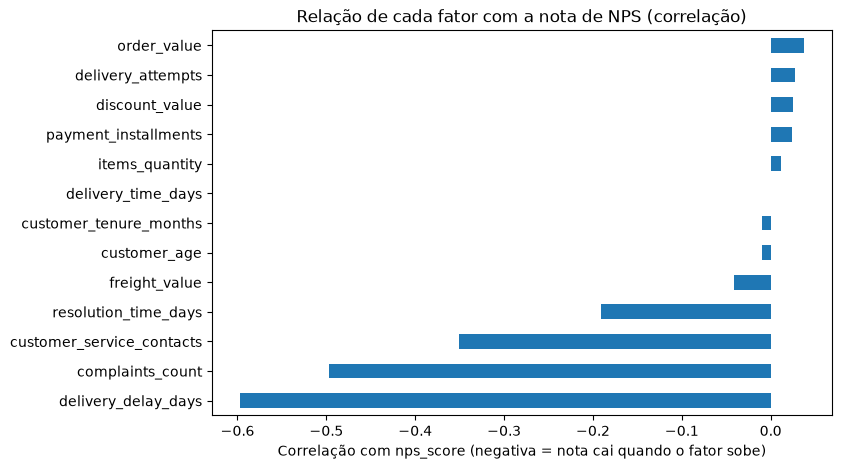

delivery_delay_days         -0.597
complaints_count            -0.497
customer_service_contacts   -0.351
resolution_time_days        -0.191
freight_value               -0.041
customer_age                -0.010
customer_tenure_months      -0.010
delivery_time_days           0.001
items_quantity               0.011
payment_installments         0.024
discount_value               0.025
delivery_attempts            0.028
order_value                  0.037
Name: nps_score, dtype: float64


In [4]:
# Lista dos fatores que vamos comparar com a nota: entrega, atendimento, pedido e perfil do cliente
colunas_operacionais = ['delivery_delay_days', 'complaints_count', 'customer_service_contacts',
                        'resolution_time_days', 'delivery_time_days', 'delivery_attempts',
                        'freight_value', 'discount_value', 'order_value', 'items_quantity',
                        'payment_installments', 'customer_age', 'customer_tenure_months']

# Calcula a correlação de cada fator com a nota
# .drop('nps_score') tira a correlação da nota com ela mesma (sempre 1)
# .sort_values() ordena da mais negativa para a mais positiva
c = df[colunas_operacionais + ['nps_score']].corr()['nps_score'].drop('nps_score').sort_values()

# Gráfico de barras horizontais (barh): uma barra por fator
plt.figure(figsize=(8, 5))
c.plot(kind='barh')
plt.title('Relação de cada fator com a nota de NPS (correlação)')
plt.xlabel('Correlação com nps_score (negativa = nota cai quando o fator sobe)')

# Salva o gráfico na pasta reports/figuras
plt.savefig('../reports/figuras/02_correlacao_fatores.png', dpi=150, bbox_inches='tight')
plt.show()

# Mostra os valores exatos, com 3 casas decimais
print(c.round(3))

**Conclusão:**
- Os fatores mais ligados à nota são: **dias de atraso na entrega** (−0,60), **número de reclamações** (−0,50), **contatos com o atendimento** (−0,35) e **tempo de resolução** (−0,19). Em todos, quanto maior o valor, menor a nota.
- Quase nada mais pesa: tempo total de entrega, tentativas de entrega, frete, desconto, valor do pedido, parcelas, idade e tempo de relacionamento têm relação próxima de zero.
- Ou seja, o que derruba a nota é **atraso (descumprir o prazo) e problemas com atendimento**, e não a entrega ser demorada em si.

### 3.2 O que mais gera detratores? Existe um ponto de ruptura?

Esta célula agrupa os pedidos por dias de atraso e mostra, para cada grupo, a nota média, a porcentagem de detratores e quantos pedidos há. Os gráficos mostram como a nota cai e os detratores aumentam conforme o atraso cresce.

                     nota_media  pct_detratores  pedidos
delivery_delay_days                                     
0                          6.86           51.62      277
1                          5.55           73.98      615
2                          4.58           87.93      646
3                          3.44           96.76      525
4                          2.44           99.26      270
5                          1.48          100.00      116
6                          1.10          100.00       34
7                          0.29          100.00       14
8                          0.00          100.00        3


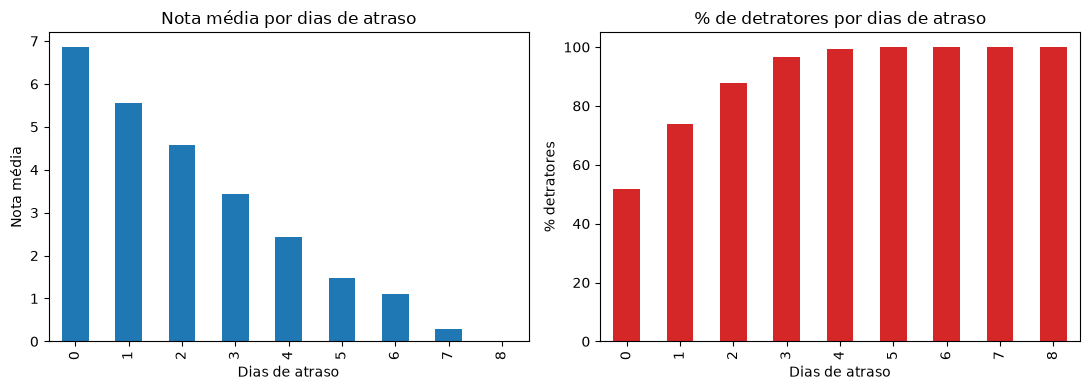

In [5]:
# Agrupa os pedidos por dias de atraso e calcula 3 números para cada grupo
atraso = df.groupby('delivery_delay_days').agg(
    nota_media=('nps_score', 'mean'),
    pct_detratores=('grupo_nps', lambda s: (s == 'detrator').mean() * 100),
    pedidos=('nps_score', 'count')
).round(2)
print(atraso)

# Dois gráficos lado a lado: 1 linha, 2 colunas
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

# Gráfico da esquerda: nota média por dia de atraso
atraso['nota_media'].plot(kind='bar', ax=ax[0])
ax[0].set_title('Nota média por dias de atraso'); ax[0].set_xlabel('Dias de atraso'); ax[0].set_ylabel('Nota média')

# Gráfico da direita: % de detratores por dia de atraso (em vermelho)
atraso['pct_detratores'].plot(kind='bar', ax=ax[1], color='tab:red')
ax[1].set_title('% de detratores por dias de atraso'); ax[1].set_xlabel('Dias de atraso'); ax[1].set_ylabel('% detratores')
plt.tight_layout()  # evita que os gráficos fiquem sobrepostos
plt.savefig('../reports/figuras/03_atraso_entrega.png', dpi=150, bbox_inches='tight') # Salva o gráfico na pasta reports/figuras
plt.show()

**Conclusão:**
- **Cada dia de atraso custa cerca de 1 ponto de nota.** Sem atraso, a nota média é ≈ 6,9; com 3 dias, cai para ≈ 3,4; com 5 dias, ≈ 1,5.
- **Ponto de ruptura:** com **3 dias de atraso ou mais, quase todos os clientes (97% a 100%) viram detratores**. Mesmo com 1 dia, já são 74%.
- Até sem atraso, 52% dos clientes são detratores, então o atraso não explica tudo.

Esta célula compara duas ideias: o que pesa mais na nota, a entrega demorar ou a entrega atrasar em relação ao prazo prometido?

In [6]:
# Correlação (de -1 a 1) entre cada fator e a nota
# Tempo total de entrega: quantos dias a entrega levou, no total
print('Correlação do tempo total de entrega com a nota:', round(df['delivery_time_days'].corr(df['nps_score']), 3))

# Dias de atraso: quantos dias depois do prazo prometido a entrega chegou
print('Correlação do atraso com a nota:', round(df['delivery_delay_days'].corr(df['nps_score']), 3))

Correlação do tempo total de entrega com a nota: 0.001
Correlação do atraso com a nota: -0.597


**Conclusão:** o tempo total de entrega praticamente não tem relação com a nota (≈ 0,00), mas o atraso tem (−0,60). O cliente não se incomoda tanto com uma entrega demorada, e sim com **não receber no prazo prometido**.

Esta célula mostra a nota média para cada nível de reclamações, de contatos com o atendimento e de dias para resolver o problema, em três gráficos lado a lado.

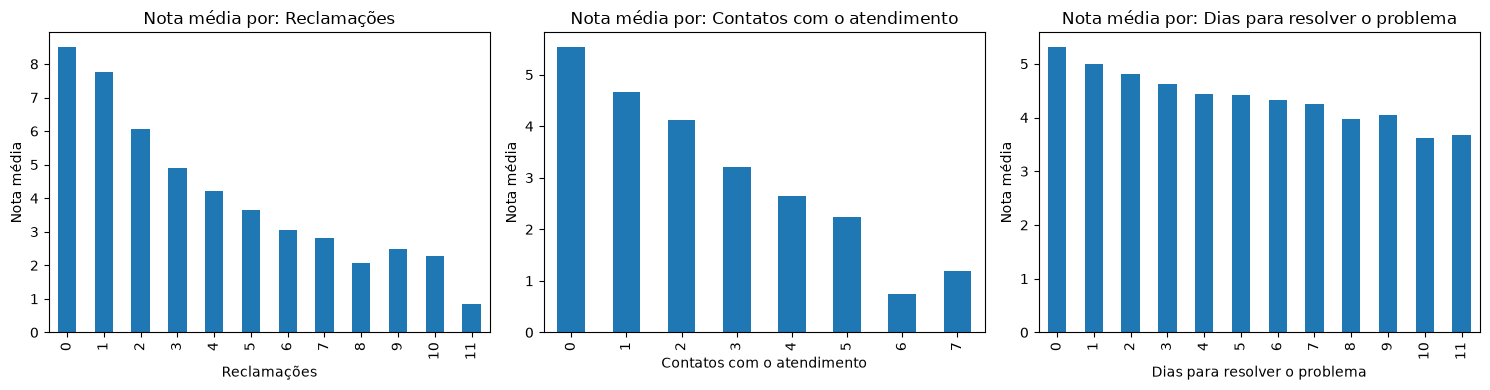

complaints_count
0     8.52
1     7.77
2     6.05
3     4.91
4     4.22
5     3.65
6     3.06
7     2.81
8     2.07
9     2.49
10    2.28
11    0.85


In [7]:
# Reclamações, contatos com o atendimento e tempo de resolução
# Três gráficos lado a lado: 1 linha, 3 colunas
fig, ax = plt.subplots(1, 3, figsize=(15, 4))

# Para cada fator, faz um gráfico de barras com a nota média por valor do fator
# zip junta cada gráfico (a), a coluna (col) e o título (titulo)
for a, col, titulo in zip(ax, ['complaints_count', 'customer_service_contacts', 'resolution_time_days'],
                          ['Reclamações', 'Contatos com o atendimento', 'Dias para resolver o problema']):
    df.groupby(col)['nps_score'].mean().plot(kind='bar', ax=a) # nota média para cada valor do fator
    a.set_title(f'Nota média por: {titulo}'); a.set_xlabel(titulo); a.set_ylabel('Nota média')
plt.tight_layout()
plt.savefig('../reports/figuras/04_atendimento.png', dpi=150, bbox_inches='tight')
plt.show()

# Nota média por número de reclamações, em números
print(df.groupby('complaints_count')['nps_score'].mean().round(2).to_string())

**Conclusão:**
- **Reclamações:** quem não reclamou dá nota média ≈ 8,5; com 3 reclamações, ≈ 4,9; com 6 ou mais, ≈ 3 ou menos.
- **Contatos com o atendimento:** a nota cai de ≈ 5,5 (nenhum contato) para ≈ 2,2 (5 contatos). Precisar falar várias vezes com o atendimento é sinal de problema.
- **Tempo de resolução:** o efeito é menor, mas constante: a nota cai de ≈ 5,3 (resolvido no mesmo dia) para ≈ 3,7 (11 dias).

### 3.3 Que tipo de cliente tem NPS mais alto ou mais baixo?

Esta célula verifica se o perfil do cliente (região, idade, tempo de relacionamento e valor do pedido) muda a nota. Primeiro divide idade, tempo de cliente e valor do pedido em faixas, depois calcula a nota média de cada grupo.

In [8]:
# Divide a idade em faixas; pd.cut usa os limites que definimos (ex.: 17 a 30 vira '18-30')
df['faixa_idade'] = pd.cut(df['customer_age'], [17, 30, 45, 60, 70], labels=['18-30', '31-45', '46-60', '61-69'])

# Divide o tempo de relacionamento (em meses) em 3 faixas
df['faixa_tempo_cliente'] = pd.cut(df['customer_tenure_months'], [0, 24, 60, 120], labels=['até 2 anos', '2 a 5 anos', 'mais de 5 anos'])

# Divide o valor do pedido em 4 grupos com o mesmo número de pedidos (qcut): os 25% menores, os do meio e os 25% maiores
df['faixa_valor_pedido'] = pd.qcut(df['order_value'], 4, labels=['25% menores', 'médio-baixo', 'médio-alto', '25% maiores'])

# Para cada característica, calcula a nota média e quantos clientes há em cada grupo
for col in ['customer_region', 'faixa_idade', 'faixa_tempo_cliente', 'faixa_valor_pedido']:
    print(df.groupby(col, observed=True)['nps_score'].agg(['mean', 'count']).round(2), '\n')

                 mean  count
customer_region             
Centro-Oeste     4.21    468
Nordeste         4.42    485
Norte            4.38    506
Sudeste          4.37    520
Sul              4.49    521 

             mean  count
faixa_idade             
18-30        4.53    602
31-45        4.24    769
46-60        4.29    714
61-69        4.56    415 

                     mean  count
faixa_tempo_cliente             
até 2 anos           4.40    489
2 a 5 anos           4.35    721
mais de 5 anos       4.39   1290 

                    mean  count
faixa_valor_pedido             
25% menores         4.22    625
médio-baixo         4.49    625
médio-alto          4.25    625
25% maiores         4.56    625 



**Conclusão:** o perfil do cliente quase não muda a nota. Região (4,2 a 4,5), faixa de idade (4,2 a 4,6), tempo de relacionamento (4,35 a 4,40) e valor do pedido (4,2 a 4,6) têm diferenças pequenas. O que diferencia um cliente satisfeito de um insatisfeito é a **experiência vivida** (atraso, reclamações e atendimento), e não quem ele é.

Esta célula compara, entre detratores, neutros e promotores, a média dos principais fatores (atraso, reclamações, contatos com o atendimento e tempo de resolução), para ver o que diferencia cada grupo.

In [9]:
# Para cada grupo de NPS (detrator, neutro, promotor), calcula a média de cada fator
# Assim dá para ver o que muda de um grupo para outro
print(df.groupby('grupo_nps')[['delivery_delay_days', 'complaints_count',
                               'customer_service_contacts', 'resolution_time_days']].mean().round(2))

           delivery_delay_days  complaints_count  customer_service_contacts  \
grupo_nps                                                                     
detrator                  2.41              4.44                       1.63   
neutro                    1.05              2.69                       1.01   
promotor                  0.72              2.27                       0.67   

           resolution_time_days  
grupo_nps                        
detrator                   5.69  
neutro                     4.62  
promotor                   3.70  


**Conclusão:** os promotores têm menos atraso, menos reclamações, menos contatos com o atendimento e resolução mais rápida do que os detratores.

## 4. Modelo preditivo (opcional): estimar o NPS antes da pesquisa

Esta célula prepara os dados (só colunas conhecidas antes da pesquisa), separa treino e teste e treina três coisas: um modelo ingênuo (que sempre chuta a nota média), a regressão linear e a árvore de decisão. No final, compara o erro de cada um no teste.

**Estratégia:** como a nota varia de 0 a 10 e 84% dos clientes são detratores, um modelo de **regressão** (prever a nota) é mais útil do que um de classificação (detrator ou não), porque a classificação quase não teria promotores para aprender. A nota prevista permite ordenar os pedidos do mais ao menos arriscado.

- **Target:** `nps_score`.
- **Entradas:** só informações operacionais conhecidas **antes da pesquisa**: perfil, pedido, entrega e atendimento. Ficam fora `csat_internal_score`, `repeat_purchase_30d` (leakage) e os identificadores.
- **Premissa:** atendimento (contatos, reclamações, tempo de resolução) já aconteceu antes da pesquisa.
- **Modelos:** regressão linear (baseline, fácil de explicar) e árvore de decisão (candidato).
- **Separação:** 80% treino e 20% teste, mantendo a proporção de detratores, neutros e promotores nos dois.
- **Avaliação:** MAE (erro médio, em pontos de nota), RMSE e R². Comparamos com um modelo ingênuo que sempre prevê a nota média.

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Colunas de entrada: só o que se conhece ANTES da pesquisa (sem leakage e sem identificadores)
entradas = ['customer_age', 'customer_tenure_months', 'order_value', 'items_quantity',
            'discount_value', 'payment_installments', 'delivery_time_days', 'delivery_delay_days',
            'freight_value', 'delivery_attempts', 'customer_service_contacts',
            'resolution_time_days', 'complaints_count', 'customer_region']

# One-Hot na região: a coluna de texto vira colunas 0/1 (uma por região)
X = pd.get_dummies(df[entradas], columns=['customer_region'], dtype=int)
y = df['nps_score']

# Separa 80% para treino e 20% para teste
# stratify: mantém a mesma proporção de detratores, neutros e promotores nos dois conjuntos
# random_state=42: a divisão é sempre a mesma, para o resultado ser repetível
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=df['grupo_nps'])
print(X_treino.shape, X_teste.shape)

# Função que mostra os 3 números de erro de um modelo no teste:
#   MAE: erro médio, em pontos de nota (quanto menor, melhor)
#   RMSE: parecido com o MAE, mas pune mais os erros grandes
#   R2: quanto da variação da nota o modelo explica (0 = nada, 1 = tudo)
def avaliar(nome, previsto):
    mae = mean_absolute_error(y_teste, previsto)
    rmse = np.sqrt(mean_squared_error(y_teste, previsto))
    r2 = r2_score(y_teste, previsto)
    print(f'{nome:32s} MAE={mae:.2f}  RMSE={rmse:.2f}  R2={r2:.2f}')

# Modelo ingênuo: sempre prevê a nota média do treino (serve de régua)
avaliar('Ingênuo (nota média)', np.full(len(y_teste), y_treino.mean()))

# Baseline: regressão linear (aprende o efeito de cada fator na nota)
linear = LinearRegression().fit(X_treino, y_treino)
avaliar('Regressão linear', linear.predict(X_teste))

# Candidato: árvore de decisão; max_depth e min_samples_leaf limitam o tamanho para não decorar os dados
arvore = DecisionTreeRegressor(max_depth=5, min_samples_leaf=20, random_state=42).fit(X_treino, y_treino)
avaliar('Árvore de decisão (prof. 5)', arvore.predict(X_teste))

(2000, 18) (500, 18)
Ingênuo (nota média)             MAE=2.11  RMSE=2.55  R2=-0.00
Regressão linear                 MAE=1.39  RMSE=1.78  R2=0.51
Árvore de decisão (prof. 5)      MAE=1.43  RMSE=1.83  R2=0.48


**Conclusão:**
- Os dois modelos melhoram bastante o modelo ingênuo: o erro médio cai de ≈ 2,1 para ≈ 1,4 ponto de nota, e o R² chega a ≈ 0,5 (o modelo explica cerca de metade da variação da nota).
- A **regressão linear foi melhor e é a mais simples de explicar**, então é a escolhida.

Esta célula mostra o efeito de cada fator na nota, segundo a regressão linear. Cada número diz quantos pontos a nota prevista muda quando o fator sobe uma unidade (mantendo os outros iguais).

delivery_delay_days            -0.937
complaints_count               -0.374
customer_service_contacts      -0.353
resolution_time_days           -0.140
customer_region_Centro-Oeste   -0.079
customer_region_Norte          -0.030


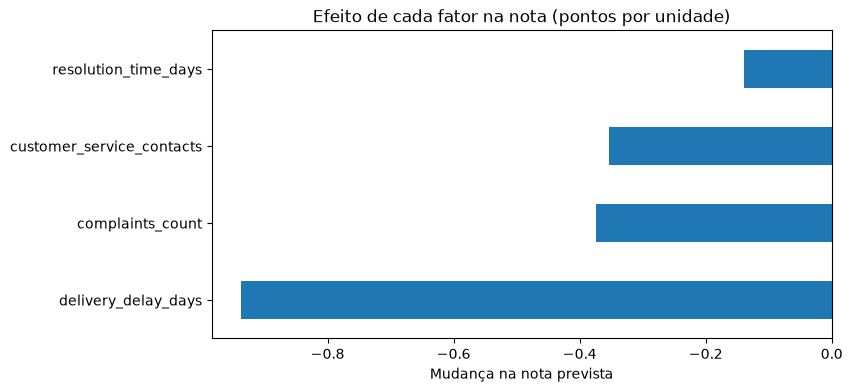

In [11]:
# Coeficientes da regressão linear: um número por coluna de entrada
# Ex.: -0,94 em delivery_delay_days = cada dia de atraso reduz a nota prevista em ≈ 0,94 ponto
coef = pd.Series(linear.coef_, index=X_treino.columns).sort_values()
print(coef.round(3).head(6).to_string()) # as 6 maiores quedas na nota

# Gráfico só com os 4 fatores principais
plt.figure(figsize=(8, 4))
coef[['delivery_delay_days', 'complaints_count', 'customer_service_contacts', 'resolution_time_days']].plot(kind='barh')
plt.title('Efeito de cada fator na nota (pontos por unidade)')
plt.xlabel('Mudança na nota prevista')
plt.savefig('../reports/figuras/05_efeito_modelo.png', dpi=150, bbox_inches='tight')
plt.show()

**Conclusão:** cada **dia de atraso** reduz a nota prevista em ≈ 0,9 ponto, cada **reclamação** em ≈ 0,4, cada **contato com o atendimento** em ≈ 0,35 e cada **dia de resolução** em ≈ 0,14. O modelo confirma o que a EDA mostrou.

Esta célula compara a nota prevista com a nota real no teste e simula um uso prático: sinalizar os pedidos com nota prevista abaixo de 3 para agir antes da pesquisa. Mede quantos sinalizados realmente ficaram insatisfeitos (precisão) e quantos clientes muito insatisfeitos o modelo encontrou (recall).

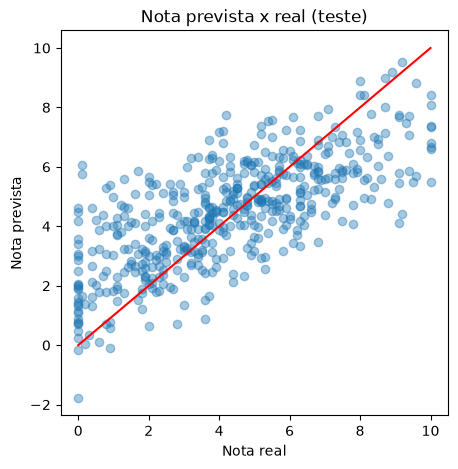

Pedidos sinalizados: 106 de 500
Dos sinalizados, quantos de fato deram nota < 3 (precisão): 0.8
Dos que deram nota < 3, quantos o modelo sinalizou (recall): 0.53
Taxa geral de nota < 3 no teste: 0.32


In [12]:
# Notas previstas pelo modelo para os pedidos do teste
previsto = linear.predict(X_teste)

# Gráfico: cada ponto é um pedido; quanto mais perto da linha vermelha, melhor a previsão
plt.figure(figsize=(5, 5))
plt.scatter(y_teste, previsto, alpha=0.4) # alpha: deixa os pontos transparentes
plt.plot([0, 10], [0, 10], color='red') # linha de acerto perfeito (previsto = real)
plt.xlabel('Nota real'); plt.ylabel('Nota prevista'); plt.title('Nota prevista x real (teste)')
plt.savefig('../reports/figuras/06_previsto_real.png', dpi=150, bbox_inches='tight')
plt.show()

# Uso prático: sinalizar pedidos com nota prevista abaixo de 3 para ação preventiva
alerta = previsto < 3                    # True = pedido sinalizado
muito_insatisfeito = y_teste.values < 3  # True = o cliente realmente deu nota abaixo de 3
print('Pedidos sinalizados:', alerta.sum(), 'de', len(alerta))

# Precisão: dos sinalizados, quantos realmente deram nota < 3
print('Dos sinalizados, quantos de fato deram nota < 3 (precisão):', round(muito_insatisfeito[alerta].mean(), 2))

# Recall: dos que deram nota < 3, quantos o modelo sinalizou
print('Dos que deram nota < 3, quantos o modelo sinalizou (recall):', round(alerta[muito_insatisfeito].mean(), 2))

# Taxa geral: referência para comparar com a precisão
print('Taxa geral de nota < 3 no teste:', round(muito_insatisfeito.mean(), 2))

**Conclusão:** ao sinalizar os pedidos com nota prevista abaixo de 3, **80% dos sinalizados realmente dão nota baixa** (a taxa geral é de ≈ 32%), e o modelo encontra **53% dos clientes muito insatisfeitos**. Isso permite agir (contato proativo, reparo do atraso) **antes** da pesquisa de NPS, concentrando o esforço onde o risco é maior.

Esta célula mostra o que aconteceria se usássemos as colunas de leakage: o R² sobe, mas essa melhora não existiria na vida real.

In [13]:
# Mesmas entradas de antes + as duas colunas de leakage (só para comparar)
X_vaza = X.assign(csat_internal_score=df['csat_internal_score'], repeat_purchase_30d=df['repeat_purchase_30d'])

# Mesma separação treino/teste (mesmo random_state), para a comparação ser justa
a, b, c, d = train_test_split(X_vaza, y, test_size=0.2, random_state=42, stratify=df['grupo_nps'])
modelo_vaza = LinearRegression().fit(a, c)

# R2 com leakage x sem leakage
print('R2 com leakage:', round(r2_score(d, modelo_vaza.predict(b)), 2), '| sem leakage:', round(r2_score(y_teste, linear.predict(X_teste)), 2))

R2 com leakage: 0.61 | sem leakage: 0.51


**Conclusão:** com as colunas de leakage o R² sobe, mas essa melhora **não existiria na vida real**, pois essas informações só ficam disponíveis depois (ou junto) da pesquisa. Por isso o modelo final não as usa.

## 5. Limitações e cuidados

- A base é sintética: os resultados mostram o raciocínio, mas podem não representar um e-commerce real.
- A nota média é muito baixa e 84% dos clientes são detratores, o que é incomum. Num caso real, valeria checar a coleta da pesquisa.
- Correlação não é causa: o atraso está muito ligado à nota, mas os dados não provam sozinhos que eliminar o atraso fará a nota subir na mesma proporção.
- Assumimos que atendimento (contatos, reclamações, resolução) acontece antes da pesquisa e que `csat_internal_score` só fica disponível depois.
- O modelo não distingue bem promotores de neutros (poucos exemplos). Serve melhor para **ordenar pedidos por risco de insatisfação** do que para prever a nota exata.
- Não há coluna de data, então não foi possível validar no tempo nem ver se o NPS mudou ao longo do tempo.